In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

#####
<font color="#2c3e50" size="6"><div style="
    font-family: sans-serif;
    font-size: 1.2em;
    font-weight: 700;
    line-height: 1.2;
    background-color: #d9e6f2;
    border-radius: 8px;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    padding: 0.5em 1em;
    margin-top: 1em;
    margin-bottom: 0.6em;
    box-shadow: 0 2px 6px rgba(0,0,0,0.1);
" align="center">
1.3 Pandas and DataFrames
</div></font>

In this chapter, we will learn how to handle datasets and how to apply basic linear algebra techniques to real-world data.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>DataFrames</b>
</div></font> 

Most datasets are stored in CSV (.csv) files, which can be opened in Excel and other spreadsheet programs. There are many publicly available sources of datasets, such as Google Dataset Search, Kaggle, NASA, Amazon, and Wikipedia. For our first example, we will use the dataset "Palmer Archipelago (Antarctica) penguin data" from Kaggle. This dataset contains measurements, sex, and location information for three species of penguins: Adelie, Chinstrap, and Gentoo.

<center> <img src="data:image/png;base64,  ...
 " width="60%"> </center>

Main library that we use for importing and manipulating datasets is `Pandas`. Find "1.3 Penguins.cvs" file and make sure it is in the same folder as this Jupyter file. We import the dataset and store it as a *DataFrame*, which is data structure commonly used in data science. A DataFrame is not the same as an array or a matrix. The key differences are:

* A DataFrame stores data in rows and columns with labeled column names.
* Columns can contain different data types (numbers, strings, categories, etc.).
* We cannot directly perform standard linear algebra operations on a DataFrame (such as matrix multiplication) without first converting it to a NumPy array.
* DataFrames are designed for data analysis and manipulation rather than pure algebraic computation.

In later sections, we will see how to convert parts of a DataFrame into arrays so that we can perform linear algebra operations. For now, let's load the dataset.

In [2]:
df=pd.read_csv('1.3 Penguins.csv')
df.shape     

(333, 7)

As we can see from `.shape` attribute, the dataset has 333 rows and 7 columns. Let's see what the data looks like.

In [3]:
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181,3750,MALE
1,Adelie,Torgersen,39.5,17.4,186,3800,FEMALE
2,Adelie,Torgersen,40.3,18.0,195,3250,FEMALE
3,Adelie,Torgersen,36.7,19.3,193,3450,FEMALE
4,Adelie,Torgersen,39.3,20.6,190,3650,MALE


We can see that the dataset contains 333 penguins. For each penguin, we are given the following information:
1. species
2. island - the island of the archipelago where the penguin was observed
3. culmen_length_mm and culmen_depth_mm - the length and depth of the upper ridge of the penguin's beak, measured in millimeters.
4. flipper_length_mm  - the length of the flipper in millimeters
5. body_mass_g - body mass measured in grams
6. sex

Let's check the data type of each column.

In [4]:
df.dtypes

species               object
island                object
culmen_length_mm     float64
culmen_depth_mm      float64
flipper_length_mm      int64
body_mass_g            int64
sex                   object
dtype: object

We can see that the dataset contains three data types. These are among the most common data types you will encounter in datasets.

1. object - generally used for text or other Python objects
2. int64 - integers
3. float64 - floating-point numbers, which can represent real numbers approximately

---

Let's look what kind of species and how many of each species we have. Since we are using DataFrame structure, we can refer to needed columns by their name instead of index.

In [5]:
df['species'].value_counts() 

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

Let's do the same for island

In [6]:
df['island'].value_counts() 

island
Biscoe       163
Dream        123
Torgersen     47
Name: count, dtype: int64

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Selecting Data</b>
</div></font> 

There are two very useful methods for selecting data from a DataFrame: `.loc` and `.iloc`. Both allow us to extract specific rows and columns, but they work in different ways. 


The `.loc` selects data using labels and Boolean conditions. It allows us to specify row labels, column labels, and conditions based on data values. For example, suppose we want to extract only the penguins that live on Biscoe Island.

In [7]:
df.loc[df['island']=='Biscoe']

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
15,Adelie,Biscoe,37.8,18.3,174,3400,FEMALE
16,Adelie,Biscoe,37.7,18.7,180,3600,MALE
17,Adelie,Biscoe,35.9,19.2,189,3800,FEMALE
18,Adelie,Biscoe,38.2,18.1,185,3950,MALE
19,Adelie,Biscoe,38.8,17.2,180,3800,MALE
...,...,...,...,...,...,...,...
328,Gentoo,Biscoe,47.2,13.7,214,4925,FEMALE
329,Gentoo,Biscoe,46.8,14.3,215,4850,FEMALE
330,Gentoo,Biscoe,50.4,15.7,222,5750,MALE
331,Gentoo,Biscoe,45.2,14.8,212,5200,FEMALE


Here is what happens step by step:

* `df['island']` selects the island column.
* `df['island'] == 'Biscoe'` creates a logical condition.
* The `==` operator checks whether two values are equal.
* The condition returns True for rows where the island is "Biscoe" and False otherwise.
* `.loc[...]` then selects only the rows where the condition is True.

This process is called **Boolean indexing**.

---

The `.iloc` method selects data using integer positions (i.e. indices). For example, suppose we want to extract the first three rows of the first and third columns. Then we would use `.iloc` method. The syntax is similar to indexing of arrays.

In [8]:
df.iloc[:3,[0,2]]

,species,culmen_length_mm
0,Adelie,39.1
1,Adelie,39.5
2,Adelie,40.3


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Changing Data Types</b>
</div></font> 

Since many linear algebra operations require numeric values, we often need to convert categorical data (such as text labels) into numbers. For example, instead of using "MALE" and "FEMALE", we can encode them numerically using 0's and 1's. There are two ways to do this. The first is to use `np.where()`, which evaluates a Boolean condition.

In [9]:
df['sex']=np.where(df['sex']=='MALE', 0, 1)
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181,3750,0
1,Adelie,Torgersen,39.5,17.4,186,3800,1
2,Adelie,Torgersen,40.3,18.0,195,3250,1
3,Adelie,Torgersen,36.7,19.3,193,3450,1
4,Adelie,Torgersen,39.3,20.6,190,3650,0


Here is how it works:
* The `np.where()` function takes three arguments: a condition, a value to use when the condition is True, and a value to use when the condition is False.
* `df['sex']=='MALE'` checks whether each value is equal to `MALE`
* If the condition is True, the first value, `0`, is assigned. Otherwise, the second value, `1`, is assigned.
* The original column is replaced with its numeric encoding.
  
If a value in the column is missing, this expression assigns `1` to it because the condition evaluates to False. If the column may contain missing values or categories other than `MALE` and `FEMALE`, we can use the `.map()` method instead:

`df['sex']=df['sex'].map({'MALE':0,'FEMALE':1})`


Here is how it works:
* `df['sex']` on the right side selects the column.
* `.map({...})` replaces each value according to the dictionary.
* The dictionary `{ 'MALE': 0, 'FEMALE': 1 }` tells Pandas how to translate each category.
* The original column is replaced with its numeric encoding.

Both methods are useful, and the choice depends on the situation. Use `.map()` to encode categorical values as numbers, especially when there are more than two categories, because a dictionary makes it easy to define multiple mappings. Use `np.where()` when assigning values based on a logical condition, such as labeling numerical values as "High" or "Low" depending on a threshold.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Saving DataFrames</b>
</div></font> 



Finally, after applying various changes to our datasets, we might want to save it as a new .csv file. Let's save the file as Penguins_map.csv. The argument `index = False` prevents pandas from writing the row index to the file, while `header=True` includes the column names as the first row.

In [10]:
df.to_csv('Penguins_map.csv', index = False, header=True) 

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Converting DataFrames to Arrays</b>
</div></font> 

As mentioned earlier, we cannot directly perform most of linear algebra operations on a DataFrame. To carry out matrix computations, we must keep only numeric columns and convert the DataFrame to a NumPy array. In our dataset, the first two columns (`species` and `island`) contain non-numeric data. We can exclude these columns by creating a new DataFrame containing only numeric columns.

In [10]:
df_num=df.select_dtypes(include='number')
df_num.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181,3750,0
1,39.5,17.4,186,3800,1
2,40.3,18.0,195,3250,1
3,36.7,19.3,193,3450,1
4,39.3,20.6,190,3650,0


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">

<strong>📌 Note:</strong> Since we know which columns we want to remove, we could also use `.iloc`. 
</div>

Once we have a purely numeric DataFrame, we can convert it into a NumPy array using `.to_numpy()`.

In [11]:
M=df_num.to_numpy()
print(M)

[[3.91e+01 1.87e+01 1.81e+02 3.75e+03 0.00e+00]
 [3.95e+01 1.74e+01 1.86e+02 3.80e+03 1.00e+00]
 [4.03e+01 1.80e+01 1.95e+02 3.25e+03 1.00e+00]
 ...
 [5.04e+01 1.57e+01 2.22e+02 5.75e+03 0.00e+00]
 [4.52e+01 1.48e+01 2.12e+02 5.20e+03 1.00e+00]
 [4.99e+01 1.61e+01 2.13e+02 5.40e+03 0.00e+00]]


Note that a NumPy array does not preserve column names. If we convert it back to a DataFrame, the columns will be assigned default integer labels. It is usually better to give these columns explicit names.

In [12]:
pd.DataFrame(M, columns=["Column1", "Column2", "Column3", "Column4", "Column5"])

,Column1,Column2,Column3,Column4,Column5
0,39.1,18.7,181.0,3750.0,0.0
1,39.5,17.4,186.0,3800.0,1.0
2,40.3,18.0,195.0,3250.0,1.0
3,36.7,19.3,193.0,3450.0,1.0
4,39.3,20.6,190.0,3650.0,0.0
...,...,...,...,...,...
328,47.2,13.7,214.0,4925.0,1.0
329,46.8,14.3,215.0,4850.0,1.0
330,50.4,15.7,222.0,5750.0,0.0
331,45.2,14.8,212.0,5200.0,1.0


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Standardization</b>
</div></font>

Notice that the values in different columns may have very different ranges. For example, values in one column may be below 100, while values in another column may be in the thousands.

When performing linear algebra operations (such as computing distances, projections, and dot products), columns with larger numerical ranges can dominate the calculations simply because of their scale. To avoid this issue, we often standardize each column. Standardization transforms each column so that its mean becomes 0 and its standard deviation becomes 1.

We first standardize each column separately. For a column with values $x_1, \cdots, x_n$, we subtract its mean $\mu$ and divide by its standard deviation $\sigma$: $$\widehat{x}_i=\frac{x_i-\mu}{\sigma}$$

We can apply this operation to every column of the data matrix $X$ at once: $$\widehat{X}=\frac{X-{\bf M}}{{\bf S}}$$
where $\bf M$ and $\bf S$ are one-dimensional arrays containing the means and standard deviations of the columns, respectively. NumPy uses broadcasting to automatically apply these arrays to the corresponding columns of $X$.

Pandas already provides methods for computing the means and standard deviations of columns. We compute the mean and standard deviation of each column using `.mean()` and `.std()` methods. We will also use the `.copy()`, which allows us to create a copy of the DataFrame, so that we can modify the new DataFrame without modifying the original one.

In [13]:
df_std = df.copy()
df_num=df.select_dtypes(include='number')

df_num_std= ( df_num - df_num.mean()) / df_num.std()

df_std[df_num.columns] = df_num_std
df_std.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,-0.894695,0.779559,-1.424608,-0.567621,-0.989542
1,Adelie,Torgersen,-0.821552,0.119404,-1.067867,-0.505525,1.007534
2,Adelie,Torgersen,-0.675264,0.424091,-0.425733,-1.188572,1.007534
3,Adelie,Torgersen,-1.333559,1.084246,-0.568429,-0.940192,1.007534
4,Adelie,Torgersen,-0.858123,1.744400,-0.782474,-0.691811,-0.989542


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b> Data Visualization</b>
</div></font> 

There are many libraries available in Python for data visualization. Some of the most commonly used libraries are Matplotlib, Plotly, and Seaborn. The first two are general-purpose visualization libraries that allow you to build a wide variety of plots from scratch. On the other hand, Seaborn is built on top of Matplotlib and provides many high-level plotting functions designed for statistical data visualization. Because of this, Seaborn is often more convenient for exploratory data analysis. In this section, we will use Seaborn.

The first visualization we will create is a pairplot for the Palmer penguins dataset. A pairplot displays scatterplots for all pairs of numerical variables in the dataset. In addition, the diagonal typically shows distributions (histograms or density plots). This allows us to quickly identify relationships between variables, clusters, outliers, and other patterns in the data.

We will also color each data point according to the penguin species using `hue="species"` argument, which helps visually separate the groups.


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #dd8452;
    background-color: rgba(250,100,60,0.16);
    margin: 0.4em 0;
">
<strong>⚠️Caution:</strong> Pairplots generate many scatterplots, one for each pair of numerical variables. As the number of variables increases, the number of plots grows rapidly, increasing rendering time. For large datasets or datasets with many variables, generating a pairplot can take noticeable time, so you may need to select a subset of variables.
</div>


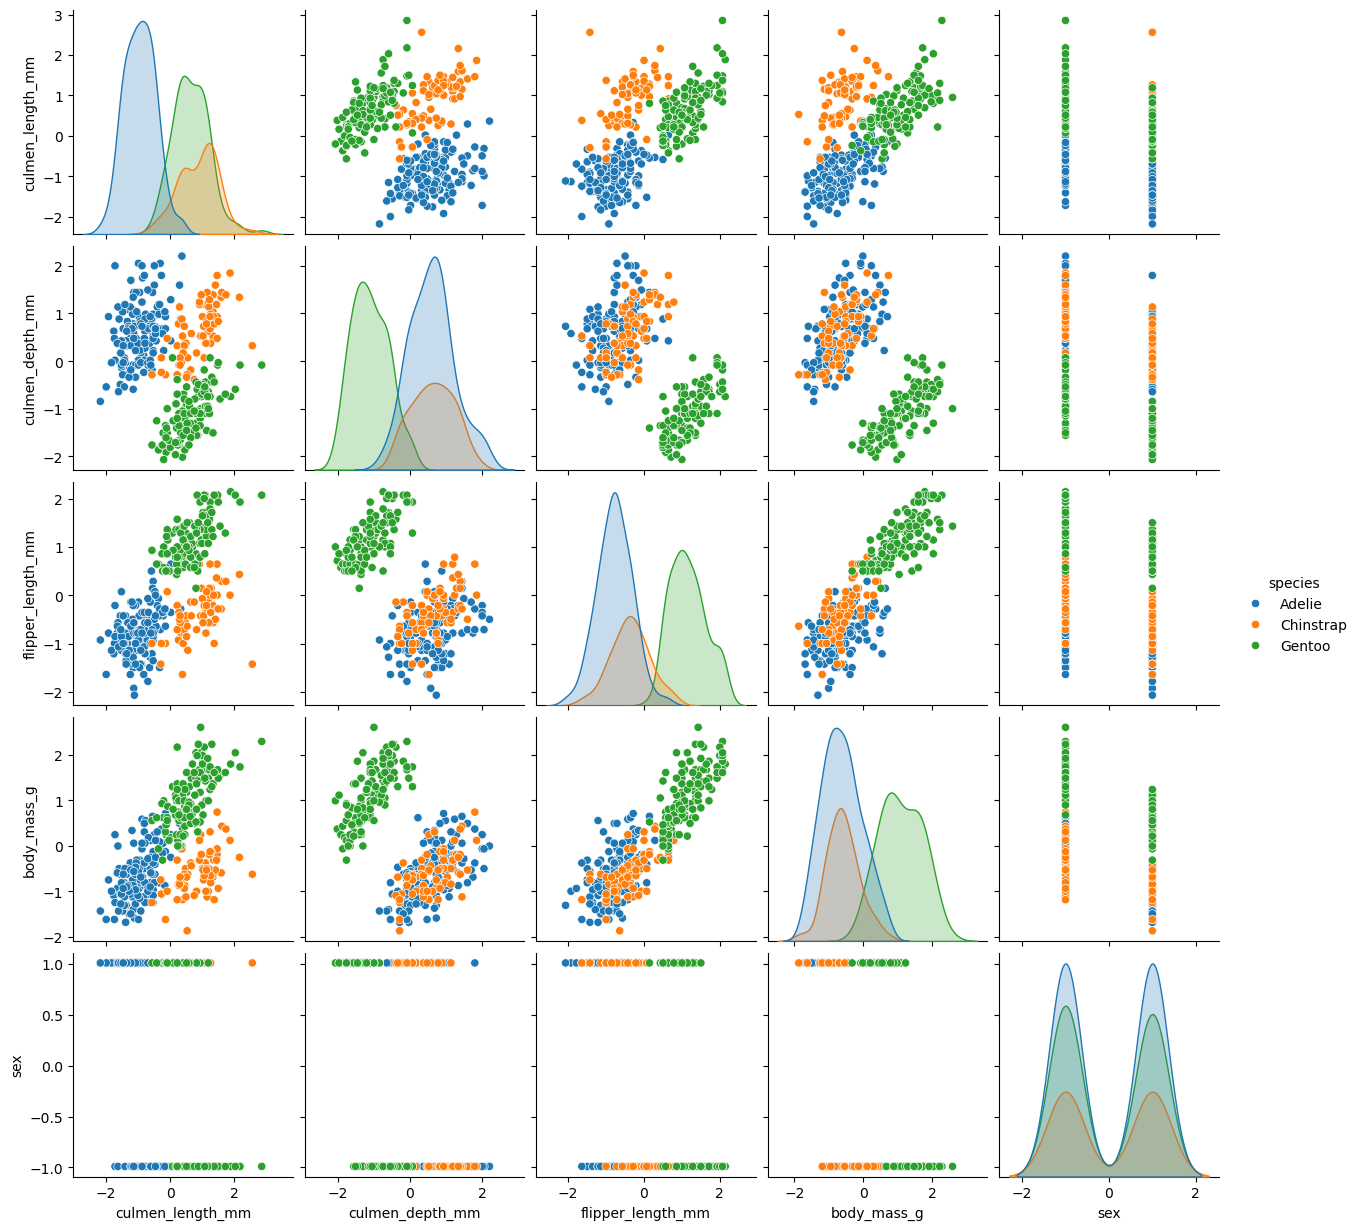

In [14]:
sns.pairplot(data=df_std, hue='species')
plt.show()

We can also create a scatterplot for a single pair of variables. Let's look at the relationship between flipper length and body mass.

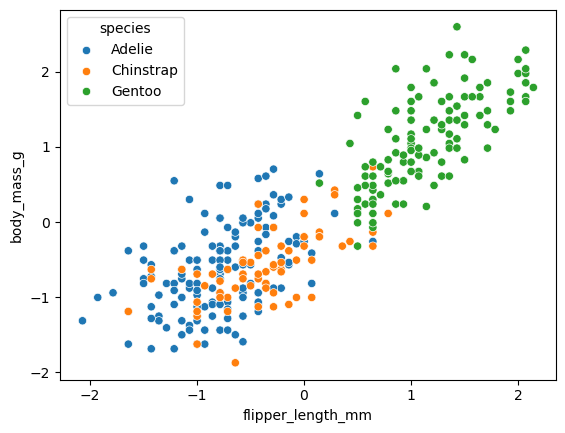

In [15]:
sns.scatterplot(data=df_std, x="flipper_length_mm",y="body_mass_g", hue='species')
plt.show()

We can also use `sns.jointplot()` to visualize the relationship between two variables and include a regression line.

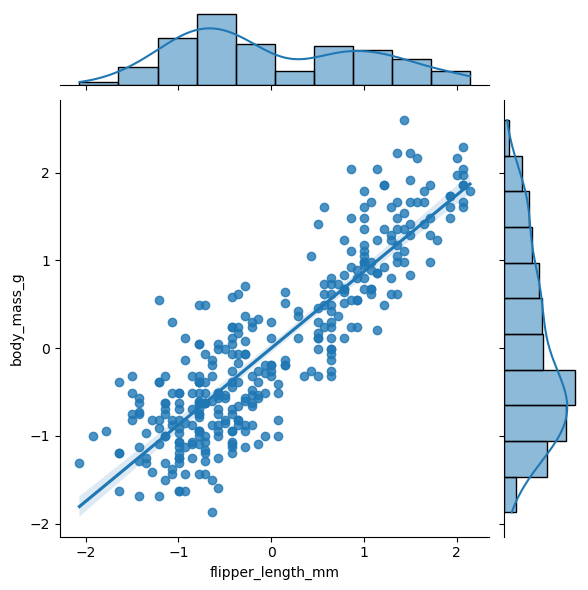

In [27]:
sns.jointplot(data=df_std, x="flipper_length_mm", y="body_mass_g", kind="reg")
plt.show()

Lastly, a heatmap is another useful visualization. We can use it to display correlations between different features. A correlation coefficient ranges from $-1$ to $1$ and measures the strength and direction of a linear relationship between two features. The value of $1$ indicates a perfect positive linear relationship, while a value of $-1$ indicates a perfect negative linear relationship. A value of $0$ indicates no linear correlation.

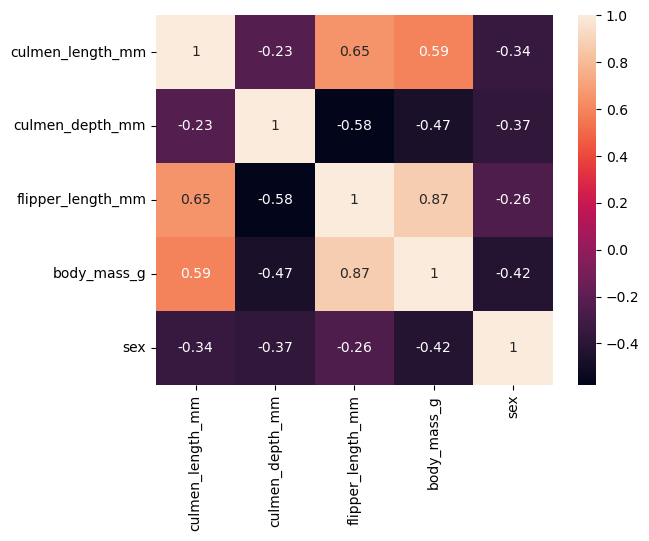

In [31]:
sns.heatmap(df_std.iloc[:,2:].corr(method="pearson"), annot=True)
plt.show()

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b> GPA Example</b>
</div></font> 


Let's consider an example where linear algebra naturally appears in a real dataset: GPA calculation.

To compute a GPA we do the following:
* Convert letter grades to numeric values (for example, A = 4.0, A− = 3.7, etc.).
* Multiply each grade by the corresponding credit value of the course
* Add the products
* Divide by the total amount of credits.

For example, let $c_1 \cdots c_n$ denote credit amount of courses and $g_1 \cdots g_n$ are corresponding grades, then the GPA is given by $$GPA=\frac{c_1g_1+c_2g_2+ \cdots c_ng_n}{c_1+c_2+\cdots c_n}$$ If we let $C=c_1+c_2+\cdots c_n$ denote the total number of credits, we can rewrite the formula as $$GPA=\frac{c_1}{C}g_1+\frac{c_2}{C}g_2+ \cdots + \frac{c_n}{C}g_n$$

This shows that GPA is a linear combination of the grades with weights $\frac{c_1}{C}, \cdots , \frac{c_n}{C}$, and so we can express it as the dot product of a grade vector ${\bf g}=\begin{bmatrix}g_1 \\ \vdots \\ g_n\end{bmatrix}$ and a credit vector ${\bf c}=\begin{bmatrix}\frac{c_1}{C}\\ \vdots \\ \frac{c_n}{C} \end{bmatrix}$.

Moreover, suppose we have a matrix $G$ where
* each row represents a student;
* each column represents a course;
* and each entry represents student's grade in that course.
  
Then the product $G{\bf c}$ calculates the GPAs of all students simultaneously.

Let's load a dataset "1.3 Grades.csv" which contains students' grades and course credit values, and compute their GPAs using matrix operations.

In [32]:
df=pd.read_csv('1.3 Grades.csv')
df.shape

(33, 16)

In [33]:
df.head()

,Student,Course1,Course2,Course3,Course4,Course5,Course6,Course7,Course8,Course9,Course10,Course11,Course12,Course13,Course14,Course15
0,Credits,3.0,3.0,4.0,4.0,2.0,6.0,3.0,3.0,4.0,4.0,2.0,6.0,2.0,3.0,3.0
1,Student01,4.0,4.0,3.7,4.0,4.0,3.7,4.0,4.0,3.7,4.0,4.0,3.7,4.0,4.0,4.0
2,Student02,3.7,3.3,3.7,3.7,3.3,3.7,3.7,3.3,3.7,3.7,3.3,3.7,3.7,3.3,3.7
3,Student03,3.0,2.7,3.3,3.0,2.7,3.0,3.3,3.0,2.7,3.0,3.3,3.0,2.7,3.0,3.3
4,Student04,2.3,2.0,2.7,2.3,2.0,2.3,2.7,2.3,2.0,2.3,2.7,2.3,2.0,2.3,2.7


Looking at the dataset, we notice that it is structured in an unusual way. The first row contains the credit values for each course, while the remaining rows contain the grades of different students.
Before performing linear algebra operations, we need to separate the credit values from the grades and remove the students' names. We will create a one-dimensional array of credit values and a two-dimensional array of grades. We will use the `.astype(float)` method to ensure that all values are represented as floating-point numbers.

In [34]:
Credits=df.iloc[0,1:].to_numpy().astype(float)
Grades=df.iloc[1:,1:].to_numpy().astype(float)

Let's divide the credit values by the total number of credits.

In [35]:
Credits=Credits/Credits.sum()
print(Credits)

[0.05769231 0.05769231 0.07692308 0.07692308 0.03846154 0.11538462
 0.05769231 0.05769231 0.07692308 0.07692308 0.03846154 0.11538462
 0.03846154 0.05769231 0.05769231]


Finally, to calculate the GPAs, we simply multiply the `Grades` matrix by the `Credits` vector.

In [36]:
GPA=Grades@Credits
print(GPA)

[3.88461538 3.6        3.00576923 2.32884615 1.67115385 2.95769231
 1.22692308 4.         3.04038462 1.38461538 3.59807692 2.38461538
 2.90961538 1.93076923 3.         2.65576923 3.17115385 2.01923077
 2.93076923 2.51923077 3.60961538 1.82884615 3.10192308 2.17115385
 2.94423077 1.25192308 2.40576923 3.08076923 2.02307692 1.48076923
 2.65576923 3.08653846]


After computing the GPAs, we often want to store them alongside the students' names in a single DataFrame. We can do this by taking the names from the original dataset and adding a GPA column.

Since we need to exclude the row containing the credit values, the original row indices will no longer be consecutive. The `.reset_index` method creates a new sequential index, and `drop=True` ensures that the old index is discarded rather than added as a new column. Since `df2` does not already contain a `GPA` column, assigning a value to `df2["GPA"]` creates one.

In [38]:
df2=df.iloc[1:,[0]]
df2=df2.reset_index(drop=True)
df2["GPA"]=GPA
df2.head()

,Student,GPA
0,Student01,3.884615
1,Student02,3.600000
2,Student03,3.005769
3,Student04,2.328846
4,Student05,1.671154


######
<font color="#0fbf0f" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Exercises</b>
</div></font> 

**1.**  
>Admission to a school is based on seven entrance exams. The final score is ccalculated as a weighted average, with weights determined by the major to which the student is applying. For the Data Science major, the weights are:
<table>
      <tr>
        <td><strong>Subject </strong> </td>
        <td><strong>Weight </strong></td>
      </tr>
      <tr>
        <td>Math </td>
        <td>0.3</td>
      </tr>
      <tr>
        <td>Physics </td>
        <td>0.1</td>
      </tr>
      <tr>
        <td>Chemistry </td>
        <td>0.05</td>
      </tr> 
      <tr>
        <td>English   </td>
        <td>0.15</td>
      </tr> 
    <tr>
        <td>History </td>
        <td>0.05</td>
      </tr>
    <tr>
        <td>Art </td>
        <td>0.05</td>
      </tr>
    <tr>
        <td>Computer Science </td>
        <td>0.3</td>
      </tr>
</table>

> Notice that the weights sum to $1$, so the final score is a weighted average.

>***a.*** Load the dataset "Grades Set.csv", which contains exam scores for 25 students.<br>
>***b.*** Calculate the final score for each student and add it as the last column to the DataFrame. Make sure order of your weights matches the order of subjects they correspond to in the dataset.<br>
>***c.*** Let $\bar{X}$ and $S$ be mean and standard deviation of the final score column. If a student's score is $\bar{X}-S$ or below, the student failed; if score is between $\bar{X}-S$ and $\bar{X}+S$, the student is placed on a waitlist; and if score is $\bar{X}+S$ or above, the student is admitted. Create a new column "Status" stating whether the student failed, was waitlisted, or was admitted.<br>
>***d.*** Print out counts for "Status" column to see how many students are in each category.<br>
>***e.*** Create pairplots for all subjects, coloring the points according to the `Status` column.<br>
>***f.*** Create a heatmap of the correlations between subjects.<br>
>***g.*** Choose the two subjects with the highest correlation. Create a scatterplot of these subjects with a regression line.<br>
>***h.*** Save the updated dataset, including the `Status` column, as "Grades Set Status.csv". Keep this file until the end of the semester.

**2.**
>***a.***  Load the dataset "Performance Set.csv". It contains information about 20 students, including the number of hours they spend studying per week, their attendance percentages, and the number of projects they have completed.<br>
>***b.*** Standardize all columns of the dataset.<br>
>***c.*** Compute `StudyIndex` as a linear combination of standardized study hours, attendance, and number of completed projects, using weights $(0.5, 0.3, 0.2)$. Add the `StudyIndex` to the DataFrame as a new column.<br>
>***d.*** Add the column `At_Risk`, that has a value `Yes` if `StudyIndex` is below $-0.75$, and `No` otherwise.<br>
>***e.*** Save the updated dataset, including the `At_Risk` column, as "Performance Set AR.csv". Keep this file until the end of the semester.